<a href="https://colab.research.google.com/github/ZainabIftikhar1204/DDI-Quantum-Model/blob/main/classical_baselines_5_seeds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Do Quantum Components Help Graph-Based DDI Prediction? Week-1 base results

**What this notebook does (maps to the Sunday deliverables)**

| Sunday item | Section |
|---|---|
| Data pipeline (DrugBank, Morgan fingerprints, PCA, negative sampling) | 2-3 |
| Fixed folds (random 80/10/10, cold-start S1/S2), saved to `artifacts/` | 3, 6 |
| Classical baselines (LogReg, RBF-SVM, GCN+MLP, parameter-matched GCN+MLP) | 4, 6 |
| First quantum model (GCN encoder + QNN decoder, plus a no-entanglement ablation) | 5, 6 |
| Preliminary falsifier check | 8 |

**How to run:** `Runtime > Run all` in Colab (or run top to bottom locally). Needs internet once, to download
DrugBank from TDC. Edit only the **Config** cell. Start with the defaults, then raise `SEEDS` to 5 seeds for the final run.

**Design (identical for every model, so the comparison is controlled)**
- Binary task on *unordered* pairs. Positives are DrugBank pairs. Negatives are uniform unobserved pairs, 1:1, drawn against *all* known positives.
- Drug features: 2048-bit Morgan (r=2) → PCA(d) fit on *training drugs only* → standardised.
- Encoder: 2-layer GCN over the drug graph (training positives only). Pair → `[hi+hj, hi*hj]` → Linear → d values → **decoder**.
- Decoder: MLP (classical) vs QNN (d qubits, angle encoding, RY/RZ + CNOT ring, ⟨Z⟩ readout). Everything before the decoder is identical.
- The QNN is simulated as an exact, differentiable statevector in PyTorch (fast), and **cross-checked against Qiskit** in section 5.

## 0. Setup

In [1]:
# Colab / fresh environment. Safe to re-run; skip if everything is already installed.
# NOTE: do not `pip install PyTDC` normally. It pins an old scikit-learn that has no wheel for new Python versions,
# so pip tries to compile it from source and fails. Install PyTDC with --no-deps and add only what it really needs.
%pip install -q rdkit qiskit
%pip install -q --no-deps PyTDC
%pip install -q tqdm fuzzywuzzy huggingface_hub tiledbsoma cellxgene-census gget "setuptools<81"
# (torch, scikit-learn, pandas, scipy, matplotlib are already in Colab; locally: pip install torch scikit-learn pandas scipy matplotlib)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytdc 1.1.15 requires dataclasses<1.0,>=0.6, which is not installed.
pytdc 1.1.15 requires evaluate==0.4.2, which is not installed.
pytdc 1.1.15 requires accelerate==0.33.0, but you have accelerate 1.15.0 which is incompatible.
pytdc 1.1.15 requires cellxgene-census==1.15.0, but you have cellxgene-census 1.18.0 which is incompatible.
pytdc 1.1.15 requires datasets<2.20.0, but you have datasets 4.8.5 which is incompatible.
pytdc 1.1.15 requires huggingface_hub<1.0,>=0.20.3, but you have huggingface-hub 1.33.0 which is incompatible.
pytdc 1.1.15 requires numpy<2.0.0,>=1.26.4, but you have numpy 2.4.6 which is incompatible.
pytdc 1.1.15 requires rdkit<2024.3.1,>=2023.9.5, but you have

## 1. Config  (the only cell you need to edit)

In [14]:
DATA_SOURCE = "tdc"        # "tdc"  -> download DrugBank DDI via PyTDC (the real dataset)
                           # "csv"  -> use CSV_PATH (a TDC-format export)
                           # "synthetic" -> pipeline smoke test ONLY, results are meaningless
CSV_PATH    = "drugbank_ddi.csv"

N_TOTAL  = 20000           # fixed labeled-pair subsample used by ALL models (0 = all pairs; quantum then gets slow)
D_LIST   = [8]             # PCA dims = number of qubits. Use [8, 12] for the full study.
SEEDS    = [0, 1, 2, 3, 4]       # use [0, 1, 2, 3, 4] for the final 5-seed run
EPOCHS   = 200
RUN_SVM  = True            # RBF-SVM is O(n^2); fine for 16k training pairs, skipped automatically above 30k
Q_LAYERS = 2               # variational layers in the QNN
Q_LR     = 0.05            # learning rate for QNN circuit parameters (classical parts use LR below)
LR       = 1e-2
OUT_DIR  = "results"
ART_DIR  = "artifacts"

## 2. Imports and data loading

In [15]:
import os, time, math, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
RDLogger.DisableLog("rdApp.*"); warnings.filterwarnings("ignore")
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(ART_DIR, exist_ok=True)
torch.set_num_threads(max(1, os.cpu_count() or 1))
print("torch", torch.__version__, "| cpus", os.cpu_count())


def make_synthetic(n_drugs=400):
    # SYNTHETIC stand-in for smoke-testing the code. NOT DrugBank. Results on it mean nothing.
    rng = np.random.default_rng(0)
    frag = ["C","CC","C(=O)","N","O","c1ccccc1","C(F)","C(Cl)","S","C#N","C(=O)O","N(C)C","C1CC1","c1ccncc1"]
    smiles, seen = [], set()
    while len(smiles) < n_drugs:
        m = Chem.MolFromSmiles("".join(rng.choice(frag, size=rng.integers(3, 9))))
        if m is not None:
            s = Chem.MolToSmiles(m)
            if s not in seen: seen.add(s); smiles.append(s)
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fp = np.stack([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles]).astype(np.float32)
    z = fp @ rng.normal(size=(2048, 4)); z = (z - z.mean(0)) / (z.std(0) + 1e-6)
    score = z @ z.T + 0.5 * rng.normal(size=(n_drugs, n_drugs))
    iu = np.triu_indices(n_drugs, 1); sel = score[iu] > np.quantile(score[iu], 0.93)
    rows = [(f"SYN{a:04d}", smiles[a], f"SYN{b:04d}", smiles[b]) for a, b in zip(iu[0][sel], iu[1][sel])]
    return pd.DataFrame(rows, columns=["Drug1_ID", "Drug1", "Drug2_ID", "Drug2"])


def load_ddi_table():
    if DATA_SOURCE == "synthetic":
        print("!" * 70, "\nSYNTHETIC DATA: pipeline smoke test only, NOT DrugBank, NOT results\n" + "!" * 70)
        df = make_synthetic()
    elif DATA_SOURCE == "csv":
        df = pd.read_csv(CSV_PATH)
    else:
        from tdc.multi_pred import DDI
        df = DDI(name="DrugBank").get_data()
        df.to_csv("drugbank_ddi.csv", index=False)      # cache a local copy (do NOT commit this file: DrugBank licence)
    need = ["Drug1_ID", "Drug1", "Drug2_ID", "Drug2"]
    missing = [c for c in need if c not in df.columns]
    assert not missing, f"missing columns {missing}; got {list(df.columns)}"
    return df[need].copy()


df = load_ddi_table()
print("rows in table:", len(df)); df.head(3)

Found local copy...
Loading...


torch 2.14.1+cpu | cpus 2


Done!


rows in table: 191808


,Drug1_ID,Drug1,Drug2_ID,Drug2
0,DB04571,CC1=CC2=CC3=C(OC(=O)C=C3C)C(C)=C2O1,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...
1,DB00855,NCC(=O)CCC(O)=O,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...
2,DB09536,O=[Ti]=O,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...


## 3. Data pipeline: drugs, positives, negatives, folds, features
Pairs are treated as unordered (`i < j`). Cold-start: 20% of drugs are held out as "new"; train/val use old-old pairs only;
**S1** = exactly one new drug, **S2** = both new.

In [16]:
def build_drugs_and_positives(df):
    smi = {}
    for a, s in zip(df.Drug1_ID, df.Drug1): smi.setdefault(a, s)
    for a, s in zip(df.Drug2_ID, df.Drug2): smi.setdefault(a, s)
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    ids, fps = [], []
    for k, s in smi.items():
        m = Chem.MolFromSmiles(s) if isinstance(s, str) else None
        if m is None: continue                       # drop drugs RDKit cannot parse
        ids.append(k); fps.append(gen.GetFingerprintAsNumPy(m).astype(np.uint8))
    index = {k: i for i, k in enumerate(ids)}
    pairs = set()
    for a, b in zip(df.Drug1_ID, df.Drug2_ID):
        if a in index and b in index and a != b:
            i, j = index[a], index[b]; pairs.add((min(i, j), max(i, j)))
    return ids, np.stack(fps), np.array(sorted(pairs), dtype=np.int64)


def sample_negatives(pos, n_drugs, n_neg, rng):
    known = set((pos[:, 0] * n_drugs + pos[:, 1]).tolist()); out = set()
    while len(out) < n_neg:
        i = rng.integers(0, n_drugs, size=2 * (n_neg - len(out)) + 16); j = rng.integers(0, n_drugs, size=i.shape)
        for a, b in zip(i.tolist(), j.tolist()):
            if a == b: continue
            a, b = (a, b) if a < b else (b, a); key = a * n_drugs + b
            if key in known or key in out: continue
            out.add(key)
            if len(out) == n_neg: break
    out = np.array(sorted(out), dtype=np.int64)
    return np.stack([out // n_drugs, out % n_drugs], 1)


def build_labeled_pairs(pos, n_drugs, rng, n_total=None):
    if n_total:
        pos_used = pos[np.sort(rng.choice(len(pos), size=n_total // 2, replace=False))]
    else:
        pos_used = pos
    neg = sample_negatives(pos, n_drugs, len(pos_used), rng)       # drawn against ALL known positives
    pairs = np.concatenate([pos_used, neg])
    y = np.concatenate([np.ones(len(pos_used)), np.zeros(len(neg))]).astype(np.float32)
    perm = rng.permutation(len(pairs))
    return pairs[perm], y[perm]


def random_split(n_pairs, rng, frac=(0.8, 0.1, 0.1)):
    perm = rng.permutation(n_pairs); a, b = int(frac[0] * n_pairs), int((frac[0] + frac[1]) * n_pairs)
    return {"train": perm[:a], "val": perm[a:b], "test": perm[b:]}


def cold_start_split(pairs, n_drugs, rng, new_frac=0.2, val_frac=0.1):
    new = np.zeros(n_drugs, bool); new[rng.choice(n_drugs, size=int(new_frac * n_drugs), replace=False)] = True
    n_new = new[pairs[:, 0]].astype(int) + new[pairs[:, 1]].astype(int)
    old_old = rng.permutation(np.where(n_new == 0)[0]); nv = int(val_frac * len(old_old))
    return {"train": old_old[nv:], "val": old_old[:nv],
            "test_s1": np.where(n_new == 1)[0], "test_s2": np.where(n_new == 2)[0]}, new


def check_split(pairs, y, split, n_drugs, new=None):
    all_idx = np.concatenate([split[k] for k in split])
    assert len(all_idx) == len(set(all_idx.tolist())), "a pair appears in more than one split"
    keys = pairs[:, 0] * n_drugs + pairs[:, 1]
    assert len(set(keys.tolist())) == len(keys), "duplicate pairs (a positive is also a negative?)"
    if new is not None:
        for k in ("train", "val"):
            p = pairs[split[k]]; assert not (new[p[:, 0]] | new[p[:, 1]]).any(), f"new drug leaked into {k}"
        p1, p2 = pairs[split["test_s1"]], pairs[split["test_s2"]]
        assert ((new[p1[:, 0]].astype(int) + new[p1[:, 1]].astype(int)) == 1).all()
        assert new[p2[:, 0]].all() and new[p2[:, 1]].all()


def pca_features(fps, train_pairs, d, seed=0):
    # PCA fit ONLY on drugs seen in training pairs, then standardise (train drugs only)
    tr = np.unique(train_pairs.ravel())
    pca = PCA(n_components=d, random_state=seed).fit(fps[tr].astype(np.float32))
    z = pca.transform(fps.astype(np.float32)); sc = StandardScaler().fit(z[tr])
    return sc.transform(z).astype(np.float32), float(pca.explained_variance_ratio_.sum())


def pair_vectors(x, pairs):
    a, b = x[pairs[:, 0]], x[pairs[:, 1]]
    return np.concatenate([a + b, a * b], axis=1)          # symmetric: drug order does not matter


ids, fps, pos = build_drugs_and_positives(df)
n = len(ids)
print(f"drugs = {n} | unique unordered positive pairs = {len(pos)} | density = {len(pos) / (n * (n - 1) / 2):.3f}")

drugs = 1705 | unique unordered positive pairs = 191392 | density = 0.132


## 4. Classical models
- **LogReg / RBF-SVM** on the compressed pair vectors (separates the effect of PCA from the effect of any graph or quantum component).
- **GCN+MLP**: GCN encoder, `Linear -> d`, then an MLP head (hidden = 16). Main baseline.
- **GCN+MLP-matched**: identical, but the MLP head is sized to have about the same number of parameters as the QNN head (the fair "same parameter budget" comparator for the falsifier).

GCN training: each epoch a random 70% of training positives form the message-passing graph and the other 30% (plus an equal number of
training negatives) are the targets, so no supervised edge is visible to the encoder. Evaluation graph = all training positives.
Best epoch by validation AUPR; F1 threshold chosen on validation only.

In [17]:
def best_f1_threshold(y, s):
    ts = np.unique(np.quantile(s, np.linspace(0.01, 0.99, 99)))
    return float(ts[int(np.argmax([f1_score(y, s >= t, zero_division=0) for t in ts]))])

def metrics(y, s, thr):
    return {"AUROC": roc_auc_score(y, s), "AUPR": average_precision_score(y, s), "F1": f1_score(y, s >= thr, zero_division=0)}

def run_sklearn(name, Xtr, ytr, Xva, yva, tests, seed=0):
    if name == "LogReg":
        m = LogisticRegression(max_iter=2000, C=1.0, random_state=seed); score = lambda X: m.predict_proba(X)[:, 1]
    else:
        m = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed); score = lambda X: m.decision_function(X)
    m.fit(Xtr, ytr); thr = best_f1_threshold(yva, score(Xva))
    return {k: metrics(y, score(X), thr) for k, (X, y) in tests.items()}


def norm_adj(n, edges, device="cpu"):
    A = torch.zeros(n, n, device=device)
    if len(edges):
        e = torch.as_tensor(edges, device=device); A[e[:, 0], e[:, 1]] = 1.0; A[e[:, 1], e[:, 0]] = 1.0
    A = A + torch.eye(n, device=device); dinv = A.sum(1).pow(-0.5)
    return dinv[:, None] * A * dinv[None, :]

class GCNEncoder(nn.Module):
    def __init__(self, in_dim, hid, out):
        super().__init__(); self.l1, self.l2 = nn.Linear(in_dim, hid), nn.Linear(hid, out)
    def forward(self, x, A):
        return A @ self.l2(torch.relu(A @ self.l1(x)))

class MLPCore(nn.Module):
    # classical decoder: d values -> hidden -> logit
    def __init__(self, d, hidden):
        super().__init__(); self.net = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, z): return self.net(z).squeeze(-1)

def mlp_hidden_for_params(d, target):
    # params(MLPCore) = hidden*(d+2) + 1  ->  choose hidden to match `target` as closely as possible
    return max(1, round((target - 1) / (d + 2)))

## 5. Quantum decoder (QNN)
**Circuit** (n = d qubits): angle encoding `RY(pi*z_i)` on each qubit, then `Q_LAYERS` times [`RY(theta)`, `RZ(phi)` on every qubit, CNOT ring],
readout `<Z>` on qubit 0, then a learnable affine `logit = a*<Z> + b`. Trainable parameters = `2*n*layers + 2`.
`entangle=False` removes the CNOTs (the ablation in the falsifier, criterion b).

The circuit is simulated **exactly** as a batched, differentiable statevector in PyTorch, so it trains jointly with the GCN. The cell below
verifies it numerically against Qiskit.

In [18]:
def ring_perm(n):
    # permutation implementing CNOT(0,1), CNOT(1,2), ..., CNOT(n-1,0) on a flat statevector (qubit 0 = most significant bit)
    idx = torch.arange(2 ** n); perm = idx.clone()
    for q in range(n):
        c, t = q, (q + 1) % n
        p = torch.where(((idx >> (n - 1 - c)) & 1) == 1, idx ^ (1 << (n - 1 - t)), idx)
        perm = perm[p]
    return perm

class QNNCore(nn.Module):
    def __init__(self, n, layers=2, entangle=True):
        super().__init__()
        self.n, self.L, self.entangle = n, layers, entangle
        self.theta = nn.Parameter(torch.randn(layers, n))
        self.phi = nn.Parameter(torch.randn(layers, n))
        self.a = nn.Parameter(torch.tensor(3.0)); self.b = nn.Parameter(torch.tensor(0.0))
        self.register_buffer("perm", ring_perm(n))

    def _U(self, l):
        c, s = torch.cos(self.theta[l] / 2), torch.sin(self.theta[l] / 2)
        ry = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.cfloat)      # (n,2,2)
        cp, sp = torch.cos(self.phi[l] / 2), torch.sin(self.phi[l] / 2)
        rz = torch.stack([torch.complex(cp, -sp), torch.complex(cp, sp)], -1)                          # (n,2) diagonal
        return rz[:, :, None] * ry                                                                       # RZ @ RY

    def expval_z0(self, angles):
        B, n = angles.shape
        c, s = torch.cos(angles / 2), torch.sin(angles / 2)
        st = torch.ones(B, 1, dtype=torch.cfloat)
        for i in range(n):                                            # product state from RY(angle_i)|0>
            q = torch.stack([c[:, i], s[:, i]], 1).to(torch.cfloat)
            st = (st[:, :, None] * q[:, None, :]).reshape(B, -1)
        for l in range(self.L):
            U = self._U(l)
            for i in range(n):
                v = st.reshape(B, 2 ** i, 2, 2 ** (n - i - 1))
                st = torch.einsum("ij,bajc->baic", U[i], v).reshape(B, -1)
            if self.entangle:
                st = st[:, self.perm]
        p = (st.real ** 2 + st.imag ** 2).reshape(B, 2, -1).sum(-1)
        return p[:, 0] - p[:, 1]

    def forward(self, z):                                           # z in (-1,1) -> angles in (-pi, pi)
        return self.a * self.expval_z0(math.pi * z) + self.b

def n_params(m): return sum(p.numel() for p in m.parameters())

In [19]:
# ---- cross-check the PyTorch statevector against Qiskit (same circuit, same random parameters) ----
def qiskit_crosscheck(n=6, layers=2, n_samples=5, seed=0):
    try:
        from qiskit import QuantumCircuit
        from qiskit.quantum_info import Statevector, SparsePauliOp
    except Exception as e:
        print("Qiskit not available, skipping cross-check:", e); return
    torch.manual_seed(seed)
    for entangle in (True, False):
        core = QNNCore(n, layers, entangle)
        z = torch.rand(n_samples, n) * 2 - 1; ang = math.pi * z
        with torch.no_grad(): mine = core.expval_z0(ang).numpy()
        obs = SparsePauliOp("I" * (n - 1) + "Z")                      # Qiskit is little-endian: rightmost char = qubit 0
        ref = []
        for k in range(n_samples):
            qc = QuantumCircuit(n)
            for i in range(n): qc.ry(float(ang[k, i]), i)
            for l in range(layers):
                for i in range(n):
                    qc.ry(float(core.theta[l, i]), i); qc.rz(float(core.phi[l, i]), i)
                if entangle:
                    for q in range(n): qc.cx(q, (q + 1) % n)
            ref.append(Statevector(qc).expectation_value(obs).real)
        err = np.abs(mine - np.array(ref)).max()
        print(f"entangle={entangle}: max |torch - qiskit| = {err:.2e}", "OK" if err < 1e-4 else "MISMATCH")
        assert err < 1e-4
qiskit_crosscheck()

entangle=True: max |torch - qiskit| = 1.26e-07 OK
entangle=False: max |torch - qiskit| = 1.65e-07 OK


In [20]:
class PairHead(nn.Module):
    # pair -> [hi+hj, hi*hj] -> Linear -> d values -> tanh -> decoder core (MLP or QNN)
    def __init__(self, emb, d, core):
        super().__init__(); self.compress = nn.Linear(2 * emb, d); self.core = core
    def forward(self, h, pairs):
        a, b = h[pairs[:, 0]], h[pairs[:, 1]]
        return self.core(torch.tanh(self.compress(torch.cat([a + b, a * b], 1))))

class GCNModel(nn.Module):
    def __init__(self, in_dim, head_kind, d, hid=64, emb=32):
        super().__init__()
        self.enc = GCNEncoder(in_dim, hid, emb)
        self.head_kind = head_kind
        q_params = 2 * d * Q_LAYERS + 2
        if head_kind == "MLP":            core = MLPCore(d, 16)
        elif head_kind == "MLP-matched":  core = MLPCore(d, mlp_hidden_for_params(d, q_params))
        elif head_kind == "QNN":          core = QNNCore(d, Q_LAYERS, True)
        elif head_kind == "QNN-noEnt":    core = QNNCore(d, Q_LAYERS, False)
        else: raise ValueError(head_kind)
        self.head = PairHead(emb, d, core)

def run_gcn(x, n_nodes, pairs, y, split, d, head_kind, seed=0, epochs=200, lr=1e-2, mp_frac=0.7):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)       # same seed -> same encoder init & same batches for every head
    x_t = torch.as_tensor(x); tr = split["train"]
    tr_pos, tr_neg = tr[y[tr] == 1], tr[y[tr] == 0]
    model = GCNModel(x.shape[1], head_kind, d)
    is_q = head_kind.startswith("QNN")
    groups = [{"params": [p for nme, p in model.named_parameters() if not nme.startswith("head.core")], "lr": lr},
              {"params": list(model.head.core.parameters()), "lr": Q_LR if is_q else lr}]
    opt = torch.optim.Adam(groups, weight_decay=5e-4)
    A_eval = norm_adj(n_nodes, pairs[tr_pos]); P = lambda idx: torch.as_tensor(pairs[idx])

    def score(idx, chunk=4096):
        model.eval(); out = []
        with torch.no_grad():
            h = model.enc(x_t, A_eval)
            for s in range(0, len(idx), chunk):
                out.append(torch.sigmoid(model.head(h, P(idx[s:s + chunk]))).numpy())
        return np.concatenate(out)

    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        perm = rng.permutation(tr_pos); k = int(mp_frac * len(perm)); mp, sup_pos = perm[:k], perm[k:]
        sup_neg = rng.choice(tr_neg, size=len(sup_pos), replace=False)
        A = norm_adj(n_nodes, pairs[mp]); sup = np.concatenate([sup_pos, sup_neg])
        loss = nn.functional.binary_cross_entropy_with_logits(model.head(model.enc(x_t, A), P(sup)),
                                                              torch.as_tensor(y[sup]))
        opt.zero_grad(); loss.backward(); opt.step()
        if ep % 5 == 4:
            v = average_precision_score(y[split["val"]], score(split["val"]))
            if v > best: best, best_state = v, {k_: t.clone() for k_, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    thr = best_f1_threshold(y[split["val"]], score(split["val"]))
    tests = [k for k in split if k.startswith("test")]
    res = {k: metrics(y[split[k]], score(split[k]), thr) for k in tests}
    return res, n_params(model), n_params(model.head.core)

## 6. Run everything
For each seed: build the labeled pairs and the folds (random + cold-start), save them, fit PCA on training drugs, then train every model
on exactly the same data. `params` = whole model, `head_params` = decoder only (this is what the QNN and the matched MLP are balanced on).

In [21]:
MODELS = ["LogReg"] + (["RBF-SVM"] if RUN_SVM else []) + ["GCN+MLP", "GCN+MLP-matched", "GCN+QNN", "GCN+QNN-noEnt"]
HEAD = {"GCN+MLP": "MLP", "GCN+MLP-matched": "MLP-matched", "GCN+QNN": "QNN", "GCN+QNN-noEnt": "QNN-noEnt"}
rows = []
t_all = time.time()
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    pairs, y = build_labeled_pairs(pos, n, rng, N_TOTAL or None)
    regimes = {"random": (random_split(len(pairs), rng), None)}
    regimes["cold"] = cold_start_split(pairs, n, rng)
    art = dict(pairs=pairs, y=y, new_mask=regimes["cold"][1])
    for r, (sp, _) in regimes.items():
        for k, v in sp.items(): art[f"{r}_{k}"] = v
    for regime, (split, new) in regimes.items():
        check_split(pairs, y, split, n, new)
        print(f"[seed {seed}] {regime}: " + ", ".join(f"{k}={len(v)}" for k, v in split.items())
              + f" | train pos-rate={y[split['train']].mean():.2f}")
        for d in D_LIST:
            x, evr = pca_features(fps, pairs[split["train"]], d, seed); art[f"x_{regime}_d{d}"] = x
            tnames = [k for k in split if k.startswith("test")]
            Xtr, ytr = pair_vectors(x, pairs[split["train"]]), y[split["train"]]
            Xva, yva = pair_vectors(x, pairs[split["val"]]), y[split["val"]]
            tests = {k: (pair_vectors(x, pairs[split[k]]), y[split[k]]) for k in tnames}
            for name in MODELS:
                if name == "RBF-SVM" and len(ytr) > 30000: continue
                t0 = time.perf_counter()
                if name in ("LogReg", "RBF-SVM"):
                    res, npar, hpar = run_sklearn(name, Xtr, ytr, Xva, yva, tests, seed), None, None
                else:
                    res, npar, hpar = run_gcn(x, n, pairs, y, split, d, HEAD[name], seed, EPOCHS, LR)
                wall = time.perf_counter() - t0
                for tk, m in res.items():
                    rows.append(dict(seed=seed, regime=regime, test=tk, d=d, model=name, n_pairs=len(pairs),
                                     pca_var=round(evr, 3), params=npar, head_params=hpar, wall_s=round(wall, 1),
                                     **{k: round(float(v), 4) for k, v in m.items()}))
                print(f"   d={d:<2} {name:<16} {wall:6.1f}s  " + "  ".join(f"{tk}: AUPR={m['AUPR']:.3f} AUROC={m['AUROC']:.3f}" for tk, m in res.items()))
    np.savez_compressed(f"{ART_DIR}/pairs_seed{seed}.npz", **art)       # fixed folds + PCA features, reused by every model
res = pd.DataFrame(rows); res.to_csv(f"{OUT_DIR}/metrics_long.csv", index=False)
print(f"\nDone in {(time.time() - t_all) / 60:.1f} min. Folds saved in {ART_DIR}/, metrics in {OUT_DIR}/")

[seed 0] random: train=16000, val=2000, test=2000 | train pos-rate=0.50
   d=8  LogReg              0.6s  test: AUPR=0.666 AUROC=0.672
   d=8  RBF-SVM            22.2s  test: AUPR=0.693 AUROC=0.707
   d=8  GCN+MLP            15.9s  test: AUPR=0.902 AUROC=0.904
   d=8  GCN+MLP-matched    15.5s  test: AUPR=0.886 AUROC=0.894
   d=8  GCN+QNN           159.2s  test: AUPR=0.906 AUROC=0.908
   d=8  GCN+QNN-noEnt     156.4s  test: AUPR=0.889 AUROC=0.898
[seed 0] cold: train=11506, val=1278, test_s1=6447, test_s2=769 | train pos-rate=0.50
   d=8  LogReg              0.3s  test_s1: AUPR=0.645 AUROC=0.675  test_s2: AUPR=0.646 AUROC=0.701
   d=8  RBF-SVM            13.5s  test_s1: AUPR=0.670 AUROC=0.702  test_s2: AUPR=0.664 AUROC=0.725
   d=8  GCN+MLP            15.5s  test_s1: AUPR=0.688 AUROC=0.709  test_s2: AUPR=0.552 AUROC=0.566
   d=8  GCN+MLP-matched    16.9s  test_s1: AUPR=0.665 AUROC=0.683  test_s2: AUPR=0.510 AUROC=0.525
   d=8  GCN+QNN           118.4s  test_s1: AUPR=0.661 AUROC=0.671  t

## 7. Results (mean ± std over seeds)

In [22]:
order = [m for m in MODELS if m in res.model.unique()]
def fmt(g, col): return f"{g[col].mean():.3f} ± {g[col].std(ddof=1) if len(g) > 1 else float('nan'):.3f}"
tab = {}
for col in ["AUPR", "AUROC", "F1"]:
    t = (res.groupby(["regime", "test", "d", "model"]).apply(lambda g: fmt(g, col)).unstack("model")[order])
    tab[col] = t; t.to_csv(f"{OUT_DIR}/summary_{col}.csv")
print("AUPR");  display(tab["AUPR"])
print("AUROC"); display(tab["AUROC"])
print("F1");    display(tab["F1"])
cost = res.groupby(["model"]).agg(params=("params", "first"), head_params=("head_params", "first"), wall_s_mean=("wall_s", "mean")).reindex(order).round(1)
print("Parameter counts and wall-clock per run (cost table)"); display(cost)
cost.to_csv(f"{OUT_DIR}/cost_table.csv")

AUPR


model                    LogReg        RBF-SVM        GCN+MLP GCN+MLP-matched  \
regime test    d                                                                
cold   test_s1 8  0.643 ± 0.009  0.669 ± 0.012  0.703 ± 0.018   0.700 ± 0.025   
       test_s2 8  0.671 ± 0.031  0.690 ± 0.037  0.584 ± 0.060   0.575 ± 0.065   
random test    8  0.653 ± 0.015  0.675 ± 0.017  0.900 ± 0.002   0.886 ± 0.014   

model                   GCN+QNN  GCN+QNN-noEnt  
regime test    d                                
cold   test_s1 8  0.672 ± 0.012  0.687 ± 0.010  
       test_s2 8  0.576 ± 0.061  0.563 ± 0.069  
random test    8  0.904 ± 0.003  0.894 ± 0.006

AUROC


model                    LogReg        RBF-SVM        GCN+MLP GCN+MLP-matched  \
regime test    d                                                                
cold   test_s1 8  0.670 ± 0.014  0.699 ± 0.015  0.718 ± 0.021   0.715 ± 0.030   
       test_s2 8  0.687 ± 0.018  0.716 ± 0.007  0.573 ± 0.020   0.565 ± 0.031   
random test    8  0.670 ± 0.013  0.710 ± 0.014  0.906 ± 0.005   0.900 ± 0.006   

model                   GCN+QNN  GCN+QNN-noEnt  
regime test    d                                
cold   test_s1 8  0.680 ± 0.012  0.692 ± 0.014  
       test_s2 8  0.566 ± 0.043  0.538 ± 0.041  
random test    8  0.909 ± 0.006  0.902 ± 0.005

F1


model                    LogReg        RBF-SVM        GCN+MLP GCN+MLP-matched  \
regime test    d                                                                
cold   test_s1 8  0.684 ± 0.011  0.692 ± 0.011  0.303 ± 0.036   0.281 ± 0.039   
       test_s2 8  0.693 ± 0.022  0.706 ± 0.024  0.059 ± 0.029   0.084 ± 0.046   
random test    8  0.683 ± 0.008  0.701 ± 0.010  0.828 ± 0.008   0.825 ± 0.007   

model                   GCN+QNN  GCN+QNN-noEnt  
regime test    d                                
cold   test_s1 8  0.284 ± 0.052  0.355 ± 0.032  
       test_s2 8  0.102 ± 0.056  0.197 ± 0.044  
random test    8  0.832 ± 0.007  0.825 ± 0.008

Parameter counts and wall-clock per run (cost table)


,params,head_params,wall_s_mean
model,,,
LogReg,NaN,NaN,0.3
RBF-SVM,NaN,NaN,15.0
GCN+MLP,3337.0,161.0,13.7
GCN+MLP-matched,3207.0,31.0,13.5
GCN+QNN,3210.0,34.0,129.3
GCN+QNN-noEnt,3210.0,34.0,129.6


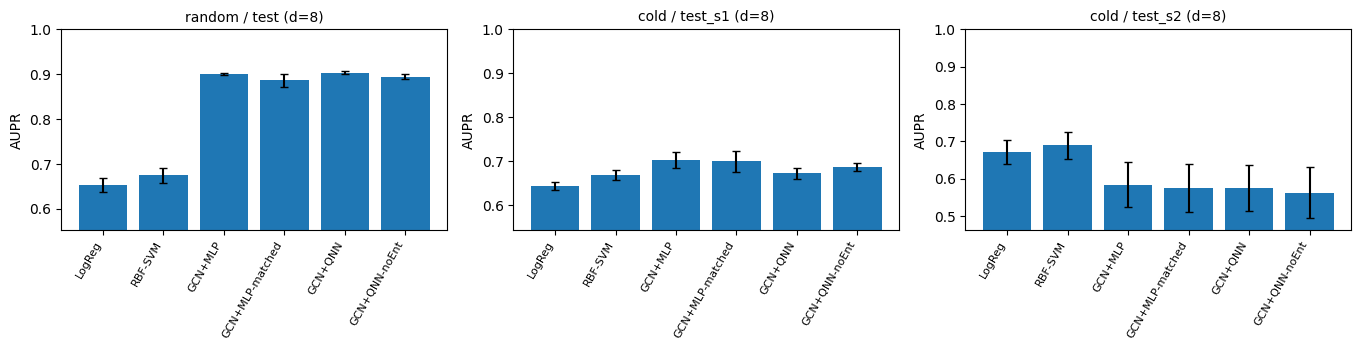

In [23]:
import matplotlib.pyplot as plt
d0 = D_LIST[0]; sub = res[res.d == d0]
groups = sub[["regime", "test"]].drop_duplicates().values.tolist()
fig, axes = plt.subplots(1, len(groups), figsize=(4.6 * len(groups), 3.6), squeeze=False)
for ax, (rg, ts) in zip(axes[0], groups):
    g = sub[(sub.regime == rg) & (sub.test == ts)].groupby("model").AUPR.agg(["mean", "std"]).reindex(order)
    ax.bar(range(len(g)), g["mean"], yerr=g["std"].fillna(0), capsize=3)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"{rg} / {ts} (d={d0})", fontsize=10); ax.set_ylabel("AUPR"); ax.set_ylim(max(0.4, g["mean"].min() - 0.1), 1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/aupr_bars.png", dpi=150); plt.show()

## 8. Preliminary falsifier check (proposal, Section II)
For each split, compute the per-seed difference ΔAUPR between the quantum model and the **parameter-matched classical** model, its mean and 95% t-CI.
- **(a)** the quantum variant does *not* help if mean Δ < 0.01 or the CI includes 0;
- **(b)** entanglement is not contributing if QNN − QNN-noEnt has a CI including 0.

The hypothesis "quantum components help" is falsified if, for every quantum variant and split, (a) or (b) holds.
With only 3 seeds the CIs are very wide, so treat this as a dry run; the real verdict needs 5 seeds.

In [24]:
from scipy import stats
def diff_ci(a, b):
    dlt = (a - b).dropna().values
    if len(dlt) < 2: return float("nan"), float("nan"), float("nan")
    m, se = dlt.mean(), dlt.std(ddof=1) / np.sqrt(len(dlt)); h = stats.t.ppf(0.975, len(dlt) - 1) * se
    return m, m - h, m + h

piv = res.pivot_table(index=["regime", "test", "d", "seed"], columns="model", values="AUPR")
out = []
for (rg, ts, d), g in piv.groupby(level=["regime", "test", "d"]):
    g = g.droplevel(["regime", "test", "d"])
    m, lo, hi = diff_ci(g["GCN+QNN"], g["GCN+MLP-matched"])
    me, loe, hie = diff_ci(g["GCN+QNN"], g["GCN+QNN-noEnt"])
    a_holds = (not np.isnan(m)) and (m < 0.01 or lo <= 0 <= hi)
    b_holds = (not np.isnan(me)) and (loe <= 0 <= hie)
    out.append(dict(regime=rg, test=ts, d=d, dAUPR_vs_matched=round(m, 4), CI=f"[{lo:.3f}, {hi:.3f}]",
                    a_no_help=a_holds, dAUPR_vs_noEnt=round(me, 4), CI_ent=f"[{loe:.3f}, {hie:.3f}]", b_no_entanglement_effect=b_holds,
                    falsified_here=a_holds or b_holds))
fal = pd.DataFrame(out); display(fal); fal.to_csv(f"{OUT_DIR}/falsifier_check.csv", index=False)
if len(SEEDS) < 5:
    print(f"NOTE: only {len(SEEDS)} seeds, so this is a dry run. Use SEEDS=[0,1,2,3,4] for the real verdict.")
print("Hypothesis 'quantum components help' falsified across ALL splits so far:", bool(fal.falsified_here.all()))

,regime,test,d,dAUPR_vs_matched,CI,a_no_help,dAUPR_vs_noEnt,CI_ent,b_no_entanglement_effect,falsified_here
0,cold,test_s1,8,-0.0273,"[-0.054, -0.001]",True,-0.0146,"[-0.024, -0.005]",False,True
1,cold,test_s2,8,0.0010,"[-0.031, 0.033]",True,0.0132,"[-0.023, 0.049]",True,True
2,random,test,8,0.0177,"[-0.002, 0.037]",True,0.0099,"[0.002, 0.018]",False,True


Hypothesis 'quantum components help' falsified across ALL splits so far: True


## 9. Package the outputs (for the GitHub repo / report)

In [25]:
import shutil
shutil.make_archive("week1_outputs", "zip", ".", OUT_DIR); print("wrote week1_outputs.zip (results tables + figure)")
try:
    from google.colab import files; files.download("week1_outputs.zip")
except Exception:
    pass

wrote week1_outputs.zip (results tables + figure)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes for the report (Methods / Limitations)
- **Graph definition:** drugs are nodes, *training* positive pairs are edges, PCA drug features are node features. Cold-start (new) drugs have no edges, so the GCN falls back to their own features (self-loop).
- **Cold-start protocol:** 20% of drugs held out as new; S1 = one new drug, S2 = both new; train/val use old-old pairs only.
- **Quantum model:** n = d qubits, angle encoding, `Q_LAYERS` × [RY, RZ, CNOT ring], ⟨Z₀⟩ readout with a learnable affine; exact statevector simulation in PyTorch, verified against Qiskit.
- **Fairness controls:** same seed gives identical encoder initialisation and identical training batches across all GCN variants; the MLP-matched head has the same number of decoder parameters as the QNN.
- **Limitation:** negatives are uniform random pairs, so a model can partly exploit drug popularity; scores are for the binary link-prediction task, not the 86 interaction types.
- **Not committed to GitHub:** `drugbank_ddi.csv` (DrugBank licence). Commit the code, `results/` and (optionally) the small `artifacts/*.npz` fold files.